# Fare Prediction Analysis with XGBoost Classifier

-> as an additional experiment, fares are classified into 3 bands: Low (0-15 USD), Medium (15-40 USD) and High (40+ USD)

### 1- Load all necessary data

In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import textwrap
from sklearn.metrics import classification_report

# Visual styling Parameters
plt.rcParams.update({
    "figure.figsize": (9, 5.5),
    "figure.dpi": 120,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.edgecolor": "#444444",
    "axes.linewidth": 0.8,
    "axes.grid": False,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "font.size": 10,
})

PRIMARY = "#4575b4"
SECONDARY = "#74add1"
ACCENT = "#d73027"
GRID = "#d9d9d9"

def style_ax(ax, xgrid=False, ygrid=False):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#666666")
    ax.spines["bottom"].set_color("#666666")
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    if xgrid:
        ax.xaxis.grid(True, linestyle="--", linewidth=0.7, alpha=0.6, color=GRID)
    if ygrid:
        ax.yaxis.grid(True, linestyle="--", linewidth=0.7, alpha=0.6, color=GRID)

    ax.set_axisbelow(True)

pd.set_option("display.float_format", "{:,.6f}".format)

def wrap_label(text, width=32):
    return "\n".join(textwrap.wrap(str(text), width=width))

# Load necessary files and data
CWD = Path(".").resolve()

# NOTE: We need this lookup table to map provider and location IDs to actual names e.g. HV0003 -> Uber...
# Download this lookup table in the CWD from https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page using:
# wget https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv

try:
    ZONE_LOOKUP_PATH = CWD / "taxi_zone_lookup.csv"
    zone_lookup = pd.read_csv(ZONE_LOOKUP_PATH)
except:
    print("Could not find taxi_zone_lookup.csv in the current working directory. Attempting to load from URL...")
    zone_lookup = pd.read_csv("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv")

zone_lookup["LocationID"] = zone_lookup["LocationID"].astype(int)

pickup_lookup = zone_lookup.rename(columns={
    "LocationID": "PULocationID",
    "Borough": "pickup_borough",
    "Zone": "pickup_zone",
    "service_zone": "pickup_service_zone",
})

dropoff_lookup = zone_lookup.rename(columns={
    "LocationID": "DOLocationID",
    "Borough": "dropoff_borough",
    "Zone": "dropoff_zone",
    "service_zone": "dropoff_service_zone",
})

feature_importances = pd.read_csv(CWD / "outputs" / "fare_xgb_classifier_feature_importances.csv")
predictions = pd.read_csv(CWD / "outputs" / "fare_xgb_classifier_test_predictions.csv")
grid_results = pd.read_csv(CWD / "outputs" / "fare_xgb_classifier_gridsearch_results.csv")

with open(CWD / "outputs" / "fare_xgb_classifier_test_metrics.json", "r") as f:
    test_metrics = json.load(f)

with open(CWD / "outputs" / "fare_xgb_classifier_best_params.json", "r") as f:
    best_params = json.load(f)

predictions["pickup_datetime"] = pd.to_datetime(predictions["pickup_datetime"], errors="coerce")
predictions = predictions.merge(pickup_lookup, on="PULocationID", how="left")
predictions = predictions.merge(dropoff_lookup, on="DOLocationID", how="left")

day_name_map = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}
PROVIDER_NAME_MAP = {"HV0002": "Juno", "HV0003": "Uber", "HV0004": "Via", "HV0005": "Lyft"}

predictions["provider_name"] = (
    predictions["hvfhs_license_num"]
    .astype(str)
    .map(PROVIDER_NAME_MAP)
    .fillna(predictions["hvfhs_license_num"].astype(str))
)

BAND_NAME_MAP = {0: "Low", 1: "Medium", 2: "High"} # reminder: 0=Low (0-15 USD), 1=Medium (15-40 USD) and 2=High (40+ USD)
predictions["actual_band_name"] = predictions["actual_band"].map(BAND_NAME_MAP)
predictions["predicted_band_name"] = predictions["predicted_band"].map(BAND_NAME_MAP)

summary_df = pd.DataFrame()
summary_df["Metric"] = ["Test Accuracy", "Test Macro F1", "Test rows"]
summary_df["Value"] = [
    test_metrics.get("test_accuracy"),
    test_metrics.get("test_macro_f1"),
    test_metrics.get("n_test_rows"),
]

print("Loaded successfully")

Loaded successfully


### 2- Summary table

In [3]:
rows = []
for key, value in best_params.items():
    rows.append({"Hyperparameter": key, "Best Value": value})
best_hyperparams_table = pd.DataFrame(rows)

print("Summary:")
display(summary_df)

print("\nBest hyperparameters:")
display(best_hyperparams_table)

Summary:


,Metric,Value
0,Test Accuracy,0.848754
1,Test Macro F1,0.842115
2,Test rows,"35,925,320.000000"



Best hyperparameters:


,Hyperparameter,Best Value
0,model__colsample_bytree,0.800000
1,model__learning_rate,0.100000
2,model__max_depth,10.000000
3,model__n_estimators,500.000000
4,model__subsample,0.800000


### 3- Confusion Matrix and Metrics Table

,precision,recall,f1-score,support
Low,0.883039,0.865127,0.873991,"13,295,822.000000"
Medium,0.813130,0.873069,0.842034,"16,506,376.000000"
High,0.884452,0.747655,0.810320,"6,123,122.000000"
macro avg,0.860207,0.828617,0.842115,"35,925,320.000000"
weighted avg,0.851159,0.848754,0.848456,"35,925,320.000000"


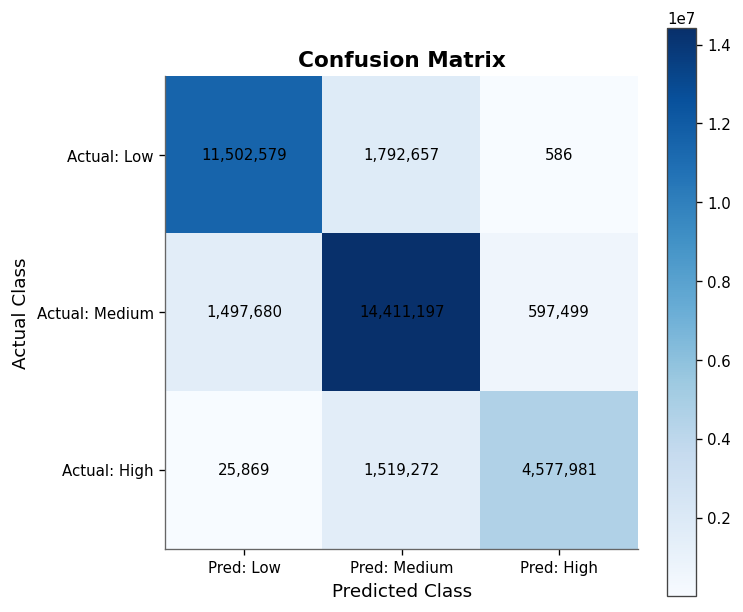

In [7]:
class_names = ["Low", "Medium", "High"]

report_df = pd.DataFrame(
    classification_report(
        predictions["actual_band"],
        predictions["predicted_band"],
        target_names=class_names,
        output_dict=True,
        digits=4,
    )
).T

display(report_df.loc[class_names + ["macro avg", "weighted avg"], ["precision", "recall", "f1-score", "support"]])

cm = pd.DataFrame(
    test_metrics["confusion_matrix"],
    index=["Actual: Low", "Actual: Medium", "Actual: High"],
    columns=["Pred: Low", "Pred: Medium", "Pred: High"],
)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm.values, cmap="Blues")

ax.set_xticks(range(len(cm.columns)))
ax.set_yticks(range(len(cm.index)))
ax.set_xticklabels(cm.columns)
ax.set_yticklabels(cm.index)
ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f"{cm.iloc[i, j]:,}", ha="center", va="center", color="black", fontsize=9)

fig.colorbar(im, ax=ax)
style_ax(ax)
plt.tight_layout()
plt.show()

### 4- Actual vs Predicted Class Counts

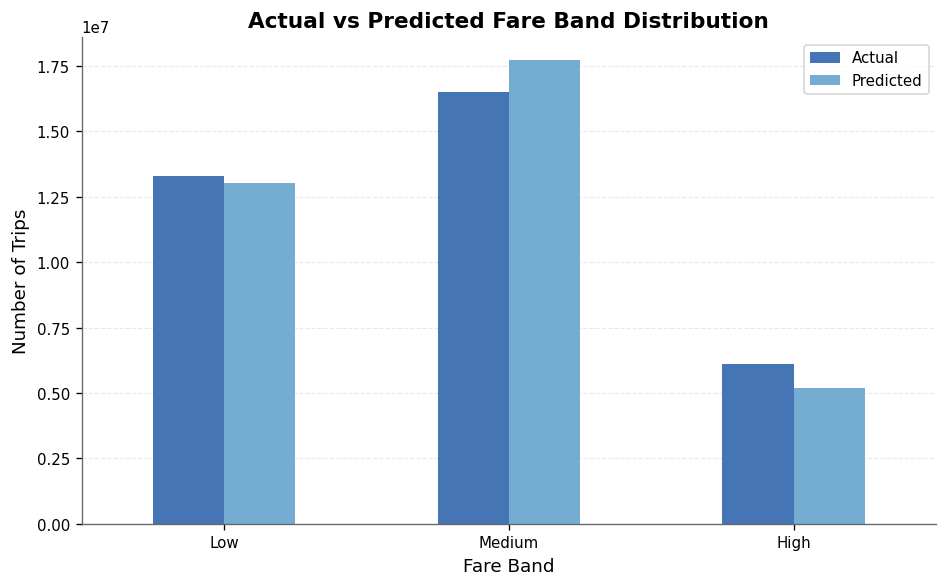

In [5]:
actual_counts = predictions["actual_band_name"].value_counts().reindex(["Low", "Medium", "High"])
pred_counts = predictions["predicted_band_name"].value_counts().reindex(["Low", "Medium", "High"])

plot_df = pd.DataFrame({
    "Actual": actual_counts,
    "Predicted": pred_counts,
})

fig, ax = plt.subplots(figsize=(8, 5))
plot_df.plot(kind="bar", ax=ax, color=[PRIMARY, SECONDARY], edgecolor="none")
ax.set_xlabel("Fare Band")
ax.set_ylabel("Number of Trips")
ax.set_title("Actual vs Predicted Fare Band Distribution")
style_ax(ax, ygrid=True)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 5- Top 15 feature importances

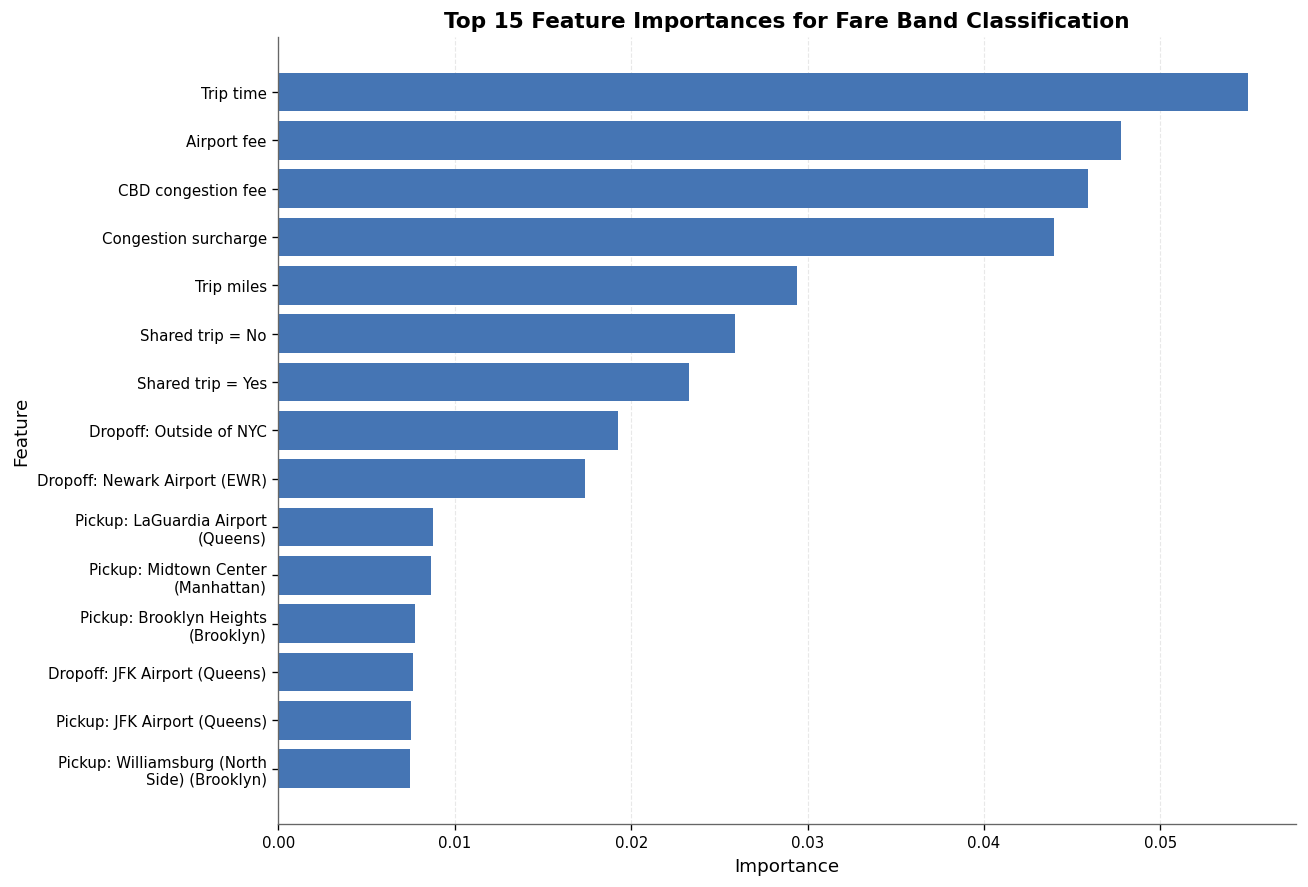

In [6]:
ZONE_NAME_MAP = dict(zip(zone_lookup["LocationID"], zone_lookup["Zone"]))
BOROUGH_NAME_MAP = dict(zip(zone_lookup["LocationID"], zone_lookup["Borough"]))

def clean_feature_name(name):
    name = str(name)

    manual_map = {
        "num__trip_miles": "Trip miles",
        "num__trip_time": "Trip time",
        "num__hour": "Hour of day",
        "num__day_of_week": "Day of week",
        "num__airport_fee": "Airport fee",
        "num__congestion_surcharge": "Congestion surcharge",
        "num__cbd_congestion_fee": "CBD congestion fee",
        "cat__shared_match_flag_Y": "Shared trip = Yes",
        "cat__shared_match_flag_N": "Shared trip = No",
    }

    if name in manual_map:
        return manual_map[name]

    if name.startswith("cat__PULocationID_"):
        location_id = int(name.split("_")[-1])
        zone = str(ZONE_NAME_MAP.get(location_id, f"Pickup zone ID {location_id}"))
        borough = BOROUGH_NAME_MAP.get(location_id)

        if pd.notna(borough) and str(borough).strip() not in {"", "Unknown"}:
            return f"Pickup: {zone} ({borough})"
        return f"Pickup: {zone}"

    if name.startswith("cat__DOLocationID_"):
        location_id = int(name.split("_")[-1])
        zone = str(ZONE_NAME_MAP.get(location_id, f"Dropoff zone ID {location_id}"))
        borough = BOROUGH_NAME_MAP.get(location_id)

        if pd.notna(borough) and str(borough).strip() not in {"", "Unknown"}:
            return f"Dropoff: {zone} ({borough})"
        return f"Dropoff: {zone}"

    if name.startswith("cat__hvfhs_license_num_"):
        provider_code = name.replace("cat__hvfhs_license_num_", "")
        return f"Provider: {PROVIDER_NAME_MAP.get(provider_code, provider_code)}"

    return name

top_n = 15
top_features = feature_importances.head(top_n).copy()
top_features["clean_feature"] = top_features["feature"].apply(clean_feature_name)
top_features["plot_label"] = top_features["clean_feature"].apply(lambda x: wrap_label(x, width=32))
top_features = top_features.sort_values("importance", ascending=True)

fig, ax = plt.subplots(figsize=(11, 7.5))
ax.barh(top_features["plot_label"], top_features["importance"], color=PRIMARY, edgecolor="none")
ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
ax.set_title(f"Top {top_n} Feature Importances for Fare Band Classification")
style_ax(ax, xgrid=True)
plt.tight_layout()
plt.show()